<a href="https://colab.research.google.com/github/samuelsambow12345-source/William-Sambow/blob/main/TA%20TabNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TabNet: Attentive Interpretable Tabular Learning**

sources :
1. https://github.com/asortubay/MyProjects/blob/main/TabNet_implementation.ipynb
2. https://ojs.aaai.org/index.php/AAAI/article/view/16826
3. https://youtu.be/g1gMB3v5kzk



# **IMPORT & LIBRARY INSTALLATION**


In [ ]:
import pandas as pd #library Python yang digunakan untuk mengolah data berbentuk tabel.
import numpy as np #perhitungan numerik dan array/matriks.
import random
import matplotlib.pyplot as plt
import seaborn as sns

from fastai.basics import * #menyediakan berbagai komponen dasar dari framework FastAI.
from fastai.tabular.all import * #untuk tabularpandas #menyiapkan komponen fastai
!pip install fast-tabnet #Install package fast-tabnet.
from fast_tabnet.core import * #Masukkan komponen Fast-TabNet yang diperlukan ke dalam program.
from itertools import product
from functools import partial
from fastai.callback.tracker import SaveModelCallback, EarlyStoppingCallback
from sklearn.metrics import precision_recall_curve

from sklearn.metrics import (
    accuracy_score as sk_accuracy_score, # Alias sklearn's accuracy_score
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# **PRE-PROCESSING & SPLITTING DATA**


In [ ]:
df_train = pd.read_excel('DATA TRAIN FIXX.xlsx')
df_test = pd.read_excel('DATA TEST FIXX.xlsx')

feature_names = [
    "ROA 1", "ROE 1", "EBITTA 1", "DE 1", "DA 1",
    "CR 1", "CA 1", "WCTA 1", "OCF 1", "WC 1",
    "NIBT 1", "REV 1", "NI 1", "TD 1", "CL 1",
    "EBITDA M 1", "EBIT M 1", "RETA 1", "CP 1"
]

target_name = [ "Label 1" ]

In [ ]:
df_train.head() #Menampilkan Data Train

,Company Common Name,Exchange Name,GICS Sector Name,Exchange Ticker,Short Exchange Name,Year,ROA,ROE,EBITTA,DE,...,TD 1,CA 1,CL 1,EBITDA M 1,EBIT M 1,RETA 1,CP 1,CP NEXT.1,Label 1,Unnamed: 57
0,Astra International Tbk PT,Indonesia Stock Exchange (formerly Jakarta SE),Industrials,ASII,IDX,2014,9.835541,19.552512,0.089609,58.30248,...,0.976991,1.000000,1.000000,0.221366,0.815423,0.925758,-0.822836,-0.837753,0,NaN
1,Astra International Tbk PT,Indonesia Stock Exchange (formerly Jakarta SE),Industrials,ASII,IDX,2013,11.253495,22.751809,0.093891,60.76299,...,0.820433,0.817176,0.935150,0.221356,0.815265,0.924769,-0.837753,-0.377718,1,NaN
2,United Tractors Tbk PT,Indonesia Stock Exchange (formerly Jakarta SE),Energy,UNTR,IDX,2022,18.173974,28.503979,0.230262,3.35386,...,-0.915298,0.623390,0.143517,0.225906,0.820780,0.939543,-0.377718,-0.818659,0,NaN
3,Astra International Tbk PT,Indonesia Stock Exchange (formerly Jakarta SE),Industrials,ASII,IDX,2012,13.513056,27.457562,0.118065,63.19393,...,0.601326,0.558993,0.473770,0.221541,0.815648,0.925120,-0.818659,-0.964413,0,NaN
4,Waskita Karya (Persero) Tbk PT,Indonesia Stock Exchange (formerly Jakarta SE),Industrials,WSKT,IDX,2018,4.156393,17.890759,0.079145,223.77956,...,0.823832,0.377796,0.545087,0.222937,0.818594,0.897031,-0.964413,-0.823433,0,NaN


In [ ]:
df_test.head() #Menampilkan Data Test

,Company Common Name,Exchange Name,GICS Sector Name,Exchange Ticker,Short Exchange Name,Year,ROA,ROE,EBITTA,DE,...,TD 1,CA 1,CL 1,EBITDA M 1,EBIT M 1,RETA 1,CP 1,CP NEXT.1,Label 1,Target_Label.1
0,Astra Agro Lestari Tbk PT,Indonesia Stock Exchange (formerly Jakarta SE),Consumer Staples,AALI,IDX,2023,3.746137,4.856901,0.043074,17.74817,...,-0.920434,-0.919231,-0.940502,0.919379,0.921693,0.972791,-0.679887,-0.717496,0,Turun
1,Astra Agro Lestari Tbk PT,Indonesia Stock Exchange (formerly Jakarta SE),Consumer Staples,AALI,IDX,2024,4.117953,5.186074,0.057547,13.74678,...,-0.936636,-0.904305,-0.950380,0.919170,0.922292,0.974761,-0.717496,-0.845140,1,Naik
2,ABM Investama Tbk PT,Indonesia Stock Exchange (formerly Jakarta SE),Energy,ABMM,IDX,2023,15.250233,45.860626,0.147672,137.05884,...,-0.999979,-0.999993,-0.999990,0.927505,0.927200,0.943093,-0.845140,-0.838758,1,Naik
3,ABM Investama Tbk PT,Indonesia Stock Exchange (formerly Jakarta SE),Energy,ABMM,IDX,2024,6.553964,17.350694,0.050732,115.23445,...,-0.999981,-0.999994,-0.999992,0.924722,0.922820,0.947498,-0.838758,-0.967314,0,Turun
4,Aspirasi Hidup Indonesia Tbk PT,Indonesia Stock Exchange (formerly Jakarta SE),Consumer Discretionary,ACES,IDX,2023,10.193245,12.593381,0.138191,15.22929,...,-0.981168,-0.935289,-0.988262,0.922292,0.924623,0.983064,-0.967314,-0.964123,1,Naik


### **DATASET SIZE INFORMATION**

In [ ]:
print("Jumlah data train :", len(df_train))
print("Jumlah data test  :", len(df_test))
print("Jumlah fitur      :", len(feature_names))

Jumlah data train : 5848
Jumlah data test  : 1219
Jumlah fitur      : 19


### **PREPARING TRAINING DATA**

In [ ]:
train_data = df_train[feature_names + target_name].copy()
#.copy() : = membuat salinan DataFrame yang berdiri sendiri
#agar aman diproses/dimodifikasi tanpa bermaksud mengubah
#DataFrame sumber df_train.
train_data.head()

,ROA 1,ROE 1,EBITTA 1,DE 1,DA 1,CR 1,CA 1,WCTA 1,OCF 1,WC 1,NIBT 1,REV 1,NI 1,TD 1,CL 1,EBITDA M 1,EBIT M 1,RETA 1,CP 1,Label 1
0,0.114674,0.016811,0.012936,-0.983532,-0.337119,-0.987316,1.000000,0.025040,-0.362151,0.802794,0.443070,1.000000,0.729824,0.976991,1.000000,0.221366,0.815423,0.925758,-0.822836,0
1,0.125173,0.023515,0.014832,-0.982837,-0.326767,-0.988089,0.817176,0.005086,-0.229826,0.705423,0.458579,0.922450,0.740788,0.820433,0.935150,0.221356,0.815265,0.924769,-0.837753,1
2,0.176416,0.035570,0.075209,-0.999053,-0.952283,-0.981990,0.623390,0.186397,0.005202,1.000000,0.528618,0.225650,0.817834,-0.915298,0.143517,0.225906,0.820780,0.939543,-0.377718,0
3,0.141904,0.033377,0.025535,-0.982150,-0.304740,-0.986582,0.558993,0.043084,-0.512694,0.771405,0.471087,0.864671,0.740982,0.601326,0.473770,0.221541,0.815648,0.925120,-0.818659,0
4,0.072622,0.013328,0.008303,-0.936792,0.160343,-0.988690,0.377796,0.006549,-0.721900,0.600290,-0.226020,-0.516225,-0.008960,0.823832,0.545087,0.222937,0.818594,0.897031,-0.964413,0


### **Consolidation of TabularPandas, DataLoaders, TabNet Model, and Learner Initialization**

#### **1. TabularPandas Initialization & Data Splitting**

In [ ]:
# Pastikan target_name menggunakan nama kolom yang benar, yaitu 'Label 1'
target_name = 'Label 1'

# Tentukan pembagian data untuk training dan validation (80% train, 20% val)
splits = RandomSplitter(valid_pct=0.2, seed=42)(range_of(train_data))

to = TabularPandas(
    train_data,
    procs=[Normalize],
    cont_names=feature_names,
    y_names=target_name,
    y_block=CategoryBlock,
    splits=splits
)

print(f"Jumlah data awal di df_train: {len(df_train)}")
print(f"Jumlah data dalam objek TabularPandas: {len(to)}")
print(f"Jumlah data latih (80%): {len(to.train)}")
print(f"Jumlah data validasi (20%): {len(to.valid)}")

Jumlah data awal di df_train: 5848
Jumlah data dalam objek TabularPandas: 5848
Jumlah data latih (80%): 4679
Jumlah data validasi (20%): 1169


#### **2. Creating DataLoaders**

In [ ]:
dls = to.dataloaders(bs=128)    # bs=128, data akan dibagi menjadi beberapa batch
                                #mengubah data yang sudah disiapkan di (to) menjadi
                                #bentuk yang siap diberikan ke model saat training.
                                #Ambil data yang sudah disiapkan oleh TabularPandas,
                                #lalu buat menjadi DataLoaders dengan ukuran batch 128."
print(f"Jumlah Kelas: {dls.c}") #jumlah class pada target (Label, 0 dan 1).

Jumlah Kelas: 2


####**3. Get embedding sizes (will be empty if no explicit categorical features are used)**


In [ ]:
emb_szs = get_emb_sz(to)   #fungsi dari FastAI yang digunakan untuk menentukan ukuran embedding bagi categorical variables/features.
                          #Walaupun penelitian kita tidak mempunyai categorical features, kode TabNetModel dari Fast-TabNet tetap dirancang
                          #supaya bisa menangani data tabular yang mungkin mempunyai categorical features.
print(f"Embedding sizes: {emb_szs}") #emb_szs tidak menunjukkan bahwa 20 fitur memiliki embedding.

Embedding sizes: []


hyperparameter dalam model tabnet ;

- n_d : Dimensions of the prediction layer (usually between 4 to 64)  -->> BUKAN GOAL UTAMA, TAPI ASUMSI

- n_a : Dimensions of the attention layer (similar to n_d)

- n_steps : Number of sucessive steps in our network (usually 3 to 10)

# **TRAINING**

# **Hyperparameter Tuning for Training**

In [ ]:
EPOCHS = 100     # Menentukan jumlah maksimum epoch untuk setiap proses training model
CLASS_WEIGHTS = torch.tensor([1.0, 1.5]).to(dls.device) # Memberikan bobot loss 1.0 untuk kelas 0 dan 1.5 untuk kelas 1, lalu menempatkannya pada perangkat yang digunakan model
                                                        #jika salah pada kelas 0, kesalahannya dihitung dengan bobot 1,0.
                                                        #Jika salah pada kelas 1, kesalahannya dihitung dengan bobot 1,5.

                                                        #pas sidang harus ngaku ada perubahan ATAU MANIPULASI UNTUK MODELNYA
def make_cbs(fname):
    cbs = [
        SaveModelCallback(
            monitor="average_precision_score",  # Memantau nilai Average Precision
            fname=fname,                         # Menentukan nama file model
            with_opt=False                       # Tidak menyimpan keadaan optimizer
        )
    ]
    return cbs  # Mengembalikan daftar callback untuk digunakan saat training

In [ ]:
#kombinasi hyperparameter
nd_search = [16, 32, 64]
na_search = [16, 32, 64]
steps_search = [3, 4, 5]
lr_search = [1e-3, 5e-4, 1e-4]

tuning_combinations = list(product(nd_search, na_search, steps_search, lr_search))
print(f"Total kombinasi di ruang pencarian: {len(tuning_combinations)}") #81 kombinasi hyperparamter

# Ambil sampel acak 15 kombinasi
random.seed(42) # Mengatur seed agar pemilihan sampel acak dapat diulang dengan hasil yang sama
trial_combinations = random.sample(tuning_combinations, 15) # Mengambil 15 kombinasi secara acak dari total 81 kombinasi untuk diuji
tuning_results = [] # Menyiapkan list kosong untuk menyimpan hasil evaluasi setiap kombinasi

for idx, (nd, na, steps, lr) in enumerate(trial_combinations, start=1): # Menguji setiap kombinasi hyperparameter yang telah dipilih
    print(f"\nEksperimen {idx}/15: n_d={nd}, n_a={na}, n_steps={steps}, lr={lr}")     # Menampilkan nomor eksperimen dan nilai hyperparameter yang sedang diuji
    set_seed(42, reproducible=True)     # Mengatur seed untuk membantu menjaga konsistensi hasil eksperimen

# Membuat model TabNet baru menggunakan kombinasi hyperparameter saat ini
    tmp_model = TabNetModel(
        emb_szs=emb_szs,
        n_cont=len(to.cont_names), #jumlah fitur input
        out_sz=dls.c, # #jumlah kelas output
        n_d=nd,  #Feature Transformer → pecah jadi d[i] & a[i]
        n_a=na,
        n_steps=steps, #Decision Step (diulang n_steps kali)
        mask_type="entmax" #Attentive Transformer
    )

# Membuat Learner untuk mengatur training, loss function, optimizer, dan metrik evaluasi
    tmp_learn = Learner(
        dls=dls,
        model=tmp_model,
        loss_func=CrossEntropyLossFlat(weight=CLASS_WEIGHTS), # Fungsi loss yang dioptimalkan; bobot kelas memengaruhi penalti kesalahan
        opt_func=partial(Adam, wd=1e-3),         # Menggunakan Adam dengan weight decay 0.001 untuk membantu regularisasi
        metrics=[accuracy, Recall(), Precision(), F1Score(), RocAucBinary(), APScoreBinary()],
        cbs=[GradientClip(1.0)]         # Membatasi besar gradien agar pembaruan bobot lebih stabil saat training
    )

 # Training model selama EPOCHS dengan learning rate sesuai kombinasi saat ini
 # make_cbs memasang callback untuk menyimpan model berdasarkan metrik pemantauan/monitor
    tmp_learn.fit_one_cycle(EPOCHS, lr_max=lr, cbs=make_cbs(f"trial_{idx}"))
    tmp_learn.load(f"trial_{idx}") # Memuat kembali model dari epoch yang disimpan oleh callback
                                   # Ini hanya mengambil epoch terbaik berdasarkan metrik monitor callback,
                                   # bukan otomatis epoch dengan recall tertinggi

    val_metrics = tmp_learn.validate() # Mengevaluasi model yang telah dimuat menggunakan data validasi
                                       # Hasilnya berupa loss dan nilai metrik sesuai urutan pada daftar metrics

    tuning_results.append({     # Menyimpan hyperparameter dan hasil evaluasi ke dalam list
        "n_d": nd, "n_a": na, "n_steps": steps, "lr": lr,
        "val_loss": val_metrics[0], "val_accuracy": val_metrics[1], #nilai-nilai pada data validasi
        "val_recall": val_metrics[2], "val_precision": val_metrics[3],
        "val_f1_score": val_metrics[4], "val_roc_auc": val_metrics[5],
        "val_auc_pr": val_metrics[6]
    })

tuning_df_1 = pd.DataFrame(tuning_results)

print("\nHyperparameter tuning selesai!")

Total kombinasi di ruang pencarian: 81

Eksperimen 1/15: n_d=16, n_a=32, n_steps=4, lr=0.0001


epoch,train_loss,valid_loss,accuracy,recall_score,precision_score,f1_score,roc_auc_score,average_precision_score,time
0,1.492924,0.888487,0.526946,0.000000,0.000000,0.000000,0.499495,0.470073,00:05
1,1.502275,0.850131,0.526946,0.000000,0.000000,0.000000,0.506768,0.472309,00:05
2,1.467690,0.880099,0.526946,0.000000,0.000000,0.000000,0.503620,0.473473,00:03
3,1.457645,0.903855,0.527802,0.000000,0.000000,0.000000,0.513130,0.482753,00:03
4,1.483324,0.920772,0.527802,0.000000,0.000000,0.000000,0.518078,0.482217,00:04
5,1.466890,0.939071,0.526946,0.001812,0.333333,0.003604,0.513218,0.478328,00:02
6,1.452937,0.893223,0.528657,0.001812,1.000000,0.003617,0.517937,0.487522,00:01
7,1.434196,0.996844,0.528657,0.001812,1.000000,0.003617,0.516069,0.482902,00:01
8,1.474017,0.961295,0.527802,0.001812,0.500000,0.003610,0.513979,0.481170,00:01
9,1.450366,0.919490,0.527802,0.001812,0.500000,0.003610,0.513218,0.477806,00:01


Better model found at epoch 0 with average_precision_score value: 0.47007335613924905.
Better model found at epoch 1 with average_precision_score value: 0.4723094138584618.
Better model found at epoch 2 with average_precision_score value: 0.4734734658477485.


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Better model found at epoch 3 with average_precision_score value: 0.4827534425001889.


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


... (74 outputs left out)

epoch,train_loss,valid_loss,accuracy,recall_score,precision_score,f1_score,roc_auc_score,average_precision_score,time
0,1.053054,0.850844,0.561163,0.371377,0.552561,0.444204,0.552044,0.508718,00:01
1,1.057703,0.779981,0.538067,0.268116,0.521127,0.354067,0.521977,0.487076,00:01
2,1.040192,0.797242,0.532079,0.259058,0.508897,0.343337,0.524871,0.486729,00:01
3,1.030707,0.786629,0.530368,0.277174,0.504950,0.357895,0.515039,0.476909,00:01
4,1.050993,0.829918,0.524380,0.246377,0.492754,0.328502,0.513709,0.473528,00:01
5,1.036886,0.871119,0.522669,0.253623,0.489510,0.334129,0.510077,0.471096,00:01
6,1.041960,0.819364,0.512404,0.266304,0.471154,0.340278,0.503623,0.467817,00:02
7,1.035082,0.843110,0.516681,0.253623,0.477816,0.331361,0.509034,0.474859,00:02
8,1.010391,0.799579,0.517536,0.324275,0.483784,0.388286,0.509322,0.474127,00:01
9,0.989597,0.799676,0.521814,0.425725,0.492662,0.456754,0.514349,0.474680,00:01


Better model found at epoch 0 with average_precision_score value: 0.5087182160129657.


/usr/local/lib/python3.13/dist-packages/fastai/learner.py:68: UserWarning: Saved file doesn't contain an optimizer state.
  elif with_opt: warn("Saved file doesn't contain an optimizer state.")



Hyperparameter tuning selesai!


In [ ]:
# Memilih hyperparameter terbaik
best_config = tuning_df.sort_values(by=['val_recall', 'val_f1_score'], ascending=[False, False]).iloc[0]

print("\n=========================================")
print("HYPERPARAMETER TERBAIK :")
print("=========================================")
print(f"n_d          : {int(best_config['n_d'])}")
print(f"n_a          : {int(best_config['n_a'])}")
print(f"n_steps      : {int(best_config['n_steps'])}")
print(f"Learning Rate: {best_config['lr']}")
print(f"Val Recall   : {best_config['val_recall']:.4f}")
print(f"Val F1-Score : {best_config['val_f1_score']:.4f}")
print("=========================================")


HYPERPARAMETER TERBAIK :
n_d          : 16
n_a          : 32
n_steps      : 4
Learning Rate: 0.0005
Val Recall   : 0.9674
Val F1-Score : 0.6438


# **Training with Best Hyperparameters**

In [ ]:
nd_1 = 16
na_1 = 32
steps_1 = 4
lr_1 = 0.0005
EPOCHS_1 = 100

CLASS_WEIGHTS_1 = torch.tensor([1.0, 1.5]).to(dls.device)

In [ ]:
# Fungsi Callback Maker untuk menyimpan model
def make_cbs(fname):
    return [
        SaveModelCallback(
            monitor="average_precision_score",  # Memantau nilai Average Precision
            fname=fname,                         # Menentukan nama file model
            with_opt=False                       # Tidak menyimpan keadaan optimizer
        )
    ]

# Mengatur seed agar hasil eksperimen lebih konsisten
set_seed(42, reproducible=True)

# Membuat model TabNet dengan hyperparameter yang telah ditentukan
tmp_model_1 = TabNetModel(
    emb_szs=emb_szs,
    n_cont=len(to.cont_names),
    out_sz=dls.c,
    n_d=nd_1,
    n_a=na_1,
    n_steps=steps_1,
    mask_type="entmax"
)

# Membuat Learner untuk mengatur training dan evaluasi model
tmp_learn_1 = Learner(
    dls=dls,                      # DataLoader training dan validasi
    model=tmp_model_1,              # Model TabNet yang akan dilatih
    loss_func=CrossEntropyLossFlat(weight=CLASS_WEIGHTS_1),  # Loss dengan bobot kelas
    opt_func=partial(Adam, wd=1e-3),                      # Optimizer Adam dengan weight decay
    metrics=[
        accuracy,                 # Mengukur proporsi prediksi yang benar
        Recall(),                 # Mengukur kemampuan mendeteksi kelas positif
        Precision(),              # Mengukur ketepatan prediksi kelas positif
        F1Score(),                # Mengukur keseimbangan precision dan recall
        RocAucBinary(),           # Mengukur kemampuan membedakan dua kelas
        APScoreBinary()           # Mengukur Average Precision
    ],
    cbs=[GradientClip(1.0)]       # Membatasi gradien untuk membantu stabilitas training
)

# Melatih model selama EPOCHS dengan learning rate 0.0001
# Callback menyimpan model berdasarkan average_precision_score terbaik ## cbs membantu melihat seberapa baik model mengenali kelas positif pada berbagai batas prediksi (threshold).
tmp_learn_1.fit_one_cycle(
    EPOCHS_1,
    lr_max=lr_1,
    cbs=make_cbs("TabNet_nd16_na32_steps4_lr0001")
)

# Memuat model dari epoch yang disimpan oleh SaveModelCallback
tmp_learn_1.load("TabNet_nd16_na32_steps4_lr0001")

# Mengevaluasi model pada data validasi
val_metrics = tmp_learn_1.validate()

# Menyimpan hasil evaluasi ke dalam DataFrame
tuning_results = [{
    "n_d": nd,"n_a": na,
    "n_steps": steps,
    "lr": lr_1,
    "val_loss": val_metrics[0],
    "val_accuracy": val_metrics[1],
    "val_recall": val_metrics[2],
    "val_precision": val_metrics[3],
    "val_f1_score": val_metrics[4],
    "val_roc_auc": val_metrics[5],
    "val_auc_pr": val_metrics[6]
}]

# Menampilkan hasil evaluasi model
print("\nTraining dan evaluasi selesai!")



epoch,train_loss,valid_loss,accuracy,recall_score,precision_score,f1_score,roc_auc_score,average_precision_score,time
0,1.484548,0.889141,0.526946,0.000000,0.000000,0.000000,0.499649,0.470130,00:01
1,1.481687,0.858397,0.526946,0.000000,0.000000,0.000000,0.506882,0.473086,00:01
2,1.444617,0.867316,0.526946,0.000000,0.000000,0.000000,0.504759,0.475464,00:01
3,1.429141,0.891487,0.526946,0.000000,0.000000,0.000000,0.513189,0.480626,00:01
4,1.437062,0.905753,0.527802,0.005435,0.500000,0.010753,0.518970,0.481498,00:01
5,1.408360,0.917714,0.525235,0.007246,0.363636,0.014210,0.513856,0.479925,00:01
6,1.375949,0.879545,0.531223,0.028986,0.571429,0.055172,0.519584,0.488769,00:01
7,1.339959,0.948207,0.525235,0.043478,0.470588,0.079602,0.517417,0.479475,00:01
8,1.322348,0.877277,0.526946,0.110507,0.495935,0.180741,0.519334,0.484612,00:01
9,1.272775,0.843263,0.507271,0.237319,0.458042,0.312649,0.515136,0.486873,00:01


Better model found at epoch 0 with average_precision_score value: 0.47013018987184824.
Better model found at epoch 1 with average_precision_score value: 0.4730863895543357.
Better model found at epoch 2 with average_precision_score value: 0.47546420035120035.
Better model found at epoch 3 with average_precision_score value: 0.4806256461539832.
Better model found at epoch 4 with average_precision_score value: 0.48149774353978114.
Better model found at epoch 6 with average_precision_score value: 0.48876908850133727.
Better model found at epoch 23 with average_precision_score value: 0.4890943158375063.
Better model found at epoch 24 with average_precision_score value: 0.49457851895219157.
Better model found at epoch 27 with average_precision_score value: 0.49941830062187453.
Better model found at epoch 33 with average_precision_score value: 0.5003054922779713.
Better model found at epoch 37 with average_precision_score value: 0.5074507479590222.
Better model found at epoch 38 with average

/usr/local/lib/python3.13/dist-packages/fastai/learner.py:68: UserWarning: Saved file doesn't contain an optimizer state.
  elif with_opt: warn("Saved file doesn't contain an optimizer state.")



Training dan evaluasi selesai!


#**Save Training Model**

In [ ]:
# Mengubah hasil evaluasi menjadi tabel
tuning_df = pd.DataFrame(tuning_results)

# Menyimpan hasil evaluasi ke file CSV
tuning_df.to_csv("tabnet_single_experiment_results.csv", index=False)

print("Hasil disimpan ke 'tabnet_single_experiment_results.csv'.")


Hasil disimpan ke 'tabnet_single_experiment_results.csv'.


### **PREPARING TEST DATA**

In [ ]:
# Pastikan target_name diambil sebagai string jika berupa list
target_column = target_name[0] if isinstance(target_name, list) else target_name

test_data = df_test[feature_names + [target_column]].copy()
test_data.head()

,ROA 1,ROE 1,EBITTA 1,DE 1,DA 1,CR 1,CA 1,WCTA 1,OCF 1,WC 1,NIBT 1,REV 1,NI 1,TD 1,CL 1,EBITDA M 1,EBIT M 1,RETA 1,CP 1,Label 1
0,0.422151,0.680749,0.231249,-0.996970,-0.656321,-0.979972,-0.919231,0.074334,-0.786929,0.352065,0.267620,-0.873688,0.471505,-0.920434,-0.940502,0.919379,0.921693,0.972791,-0.679887,0
1,0.427580,0.680978,0.252417,-0.997653,-0.725798,-0.971420,-0.904305,0.152132,-0.761651,0.381925,0.270492,-0.867176,0.472979,-0.936636,-0.950380,0.919170,0.922292,0.974761,-0.717496,1
2,0.590131,0.709242,0.384245,-0.976598,0.193860,-0.989373,-0.999993,-0.058212,-0.855251,0.302761,0.247010,-0.999991,0.454519,-0.999979,-0.999990,0.927505,0.927200,0.943093,-0.845140,1
3,0.463150,0.689431,0.242449,-0.980325,0.153327,-0.988473,-0.999994,-0.035241,-0.855248,0.302762,0.247007,-0.999993,0.454517,-0.999981,-0.999992,0.924722,0.922820,0.947498,-0.838758,0
4,0.516290,0.686125,0.370377,-0.997400,-0.698961,-0.917734,-0.935289,0.668220,-0.815908,0.377981,0.260286,-0.953604,0.466911,-0.981168,-0.988262,0.922292,0.924623,0.983064,-0.967314,1


##**Step 1: Preparing Test DataLoader and Getting Raw Predictions**

In [ ]:
# Menyelaraskan nama kolom agar tidak ada perbedaan penulisan seperti 'CA 1' vs 'CA1'
test_data_aligned = test_data.copy()
if 'CA 1' in test_data_aligned.columns and 'CA1' not in test_data_aligned.columns:
    test_data_aligned = test_data_aligned.rename(columns={'CA 1': 'CA1'})

# Membuat test dataloader menggunakan data yang kolomnya sudah disesuaikan
dls_test = tmp_learn_1.dls.test_dl(test_data_aligned)

# Mengambil prediksi mentah berupa probabilitas dan target aktual
y_prob, y_test = tmp_learn_1.get_preds(dl=dls_test)

## **Step 2: Processing Predicted Probabilities**

In [ ]:
# Mengambil nilai probabilitas untuk kelas positif (kelas 1)
y_prob_positive = y_prob[:, 1].numpy()

# Menentukan label prediksi berdasarkan probabilitas tertinggi (argmax)
y_pred = np.argmax(y_prob.numpy(), axis=1) #->cari tahu axis

## **Step 3: Calculating and Displaying Evaluation Metrics**

HASIL EVALUASI FASTTABNET (TERLATIH)
Accuracy  : 0.5176
Precision : 0.5388
Recall    : 0.8138
F1-Score  : 0.6483
ROC-AUC   : 0.4658


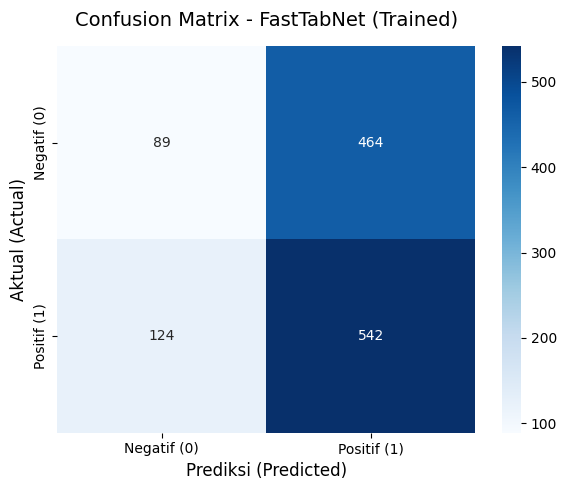

In [ ]:
# Menghasilkan ulang prediksi menggunakan model terlatih
dls_test = tmp_learn_1.dls.test_dl(test_data_aligned)
y_prob, _ = tmp_learn_1.get_preds(dl=dls_test)
y_prob_positive = y_prob[:, 1].numpy()
y_pred = np.argmax(y_prob.numpy(), axis=1)

# Mengambil label aktual
target_column = target_name[0] if isinstance(target_name, list) else target_name
y_test = test_data_aligned[target_column].values

# Evaluasi Metriks menggunakan Scikit-Learn
calculated_accuracy = sk_accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob_positive)

# Menghitung Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Menampilkan hasil evaluasi teks
print("=====================================")
print("HASIL EVALUASI FASTTABNET (TERLATIH)")
print("=====================================")
print(f"Accuracy  : {calculated_accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print("=====================================")

# Visualisasi Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negatif (0)", "Positif (1)"],
    yticklabels=["Negatif (0)", "Positif (1)"]
)
plt.title("Confusion Matrix - FastTabNet (Trained)", fontsize=14, pad=15)
plt.ylabel("Aktual (Actual)", fontsize=12)
plt.xlabel("Prediksi (Predicted)", fontsize=12)
plt.tight_layout()
plt.show()